# Week 6 Task 5: sensitivity of Sahel rainfall to SST

J = Sahel-mean rainfall (10N-20N, 20W-40E) averaged over a short window, as a function of an SST change at every
ocean grid point. Same recipe as Task 3: build J, check the gradient against finite differences, then make a map
with one reverse-mode pass.

**Answer.**
- **Gradient vs finite difference:** forward mode says 1 K of uniform ocean warming lowers Sahel rain by
  **0.0027 (6 h), 0.015 (1 day) and 0.028 (2 days) mm/day**. Finite differences agree on the sign but are mostly
  **1.3-2.9x larger** (the 2-day, h = 0.1 K value is the exception), and they change with the step size h (for example 1 day: 0.021 with h = 1 K, 0.028 with
  h = 0.1 K). So the agreement is only rough.
- **Dot-product test passes:** `sum(map)` matches `jax.jvp` to within 0.4% for uniform warming, and within 0.1% (off
  Senegal) and 3% (Gulf of Guinea) for the regional boxes. The map really is the model's gradient.
- **Map:** the sensitivity is local. Almost all of it is on the West African coast just south and west of the
  Sahel box (Senegal to Sierra Leone, about 5N-15N). Warming those coastal points lowers Sahel rain. The rest of
  the world is near zero apart from stripes that look like spectral ringing.
- **Cost:** one forward or reverse pass takes 12-24 s on a laptop CPU (M-series), about the same for every window.
  A finite-difference map would need one run per ocean point (3,080 runs here, or about 11 hours at 13 s each).

In [1]:
from importlib.resources import files
import time
import jax
import jax.numpy as jnp
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from jcm import load_states_from_xarray
from jcm.forcing import ForcingData
from jcm.model import Model
from jcm.physics.speedy.speedy_coords import get_speedy_coords
from jcm.terrain import TerrainData

## Setup

The model, spin-up and ocean mask follow the Task 3 code on the course page. The only change is J: instead of
global-mean OLR it is the area-weighted rainfall over the Sahel box (10N-20N, 20W-40E), from
`surface_exchange.precipitation`, converted from kg m-2 s-1 to mm/day (x 86400).

In [2]:
coords = get_speedy_coords(spectral_truncation=31, layers=8)
data = files("jcm") / "data/bc/t30/clim"
terrain = TerrainData.from_file(data / "terrain.nc", coords=coords)
bc = ForcingData.from_file(data / "forcing.nc", coords=coords, align_mode="wrap_year")
model = Model(coords=coords, terrain=terrain, time_step=30)

# Spin up from rest, then start every experiment from the same state
t = time.time()
spinup = model.run(forcing=bc, total_time=60, save_interval=60).to_xarray()
ic = load_states_from_xarray(spinup.isel(time=-1).sortby("level"))
print(f"spin-up: {time.time() - t:.0f} s")

ocean = jnp.asarray(np.asarray(terrain.fmask) < 0.5)        # (lon, lat), True over ocean
lat, lon = spinup.lat.values, spinup.lon.values
w = np.cos(np.deg2rad(lat))
weights = jnp.broadcast_to(jnp.asarray(w / w.mean()), ocean.shape)

/Users/romanrespicio/miniforge3/envs/jcm-model/lib/python3.12/site-packages/jcm/data/bc/interpolate.py:105: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([ds_interp, passthrough])


/Users/romanrespicio/miniforge3/envs/jcm-model/lib/python3.12/site-packages/jcm/data/bc/interpolate.py:53: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([daily_time_vars, ds_monthly[non_time_vars]])


spin-up: 50 s


In [3]:
LON, LAT = np.meshgrid(lon, lat, indexing="ij")              # lon is 0-360, so 20W = 340

def box(lat0, lat1, lon0, lon1):
    """1 inside a lat/lon box (lon in -180..180, may cross 0), 0 outside."""
    L = np.where(LON > 180, LON - 360, LON)
    return ((LAT >= lat0) & (LAT <= lat1) & (L >= lon0) & (L <= lon1)).astype(float)

sahel = box(10, 20, -20, 40)
sahel_w = jnp.asarray(sahel * w[None, :])
sahel_w = sahel_w / sahel_w.sum()
print(f"Sahel box: {int(sahel.sum())} grid points, {int((sahel * np.asarray(ocean)).sum())} of them ocean")

def sahel_rain(dsst, window):
    """Sahel-mean rainfall (mm/day) averaged over `window` days, with SST + dsst over the ocean."""
    sst = bc.sea_surface_temperature
    forcing = bc.copy(sea_surface_temperature=sst.replace(values=sst.values + dsst * ocean))
    out = model.run(initial_state=ic, forcing=forcing, total_time=window,
                    save_interval=window, output_averages=True).to_xarray()
    pr = out["surface_exchange.precipitation"].isel(time=-1).data
    return 86400 * jnp.sum(sahel_w * pr)

zero = jnp.zeros(ocean.shape)
one = jnp.ones_like(zero)

Sahel box: 32 grid points, 2 of them ocean


## Gradient vs finite difference, and the map

For each window: forward mode (`jax.jvp`) gives dJ for 1 K of uniform ocean warming; the centred finite difference
`(J(+h) - J(-h)) / 2h` uses h = 1 K and 0.1 K; reverse mode (`jax.vjp`) gives the full map in one pass. `sum(map)`
should equal the forward-mode number (dot-product test with the uniform pattern).

In [4]:
WINDOWS = [0.25, 1.0, 2.0]   # days
res = {}
for window in WINDOWS:
    J = lambda d: sahel_rain(d, window)
    t = time.time(); J0, dJ = jax.jvp(J, (zero,), (one,)); t_fwd = time.time() - t
    fd1 = (J(1.0 * one) - J(-1.0 * one)) / 2.0
    fd01 = (J(0.1 * one) - J(-0.1 * one)) / 0.2
    t = time.time(); _, back = jax.vjp(J, zero); (smap,) = back(1.0); t_rev = time.time() - t
    res[window] = dict(J0=float(J0), jvp=float(dJ), fd1=float(fd1), fd01=float(fd01),
                       dot=float(jnp.sum(smap * one)), t_fwd=t_fwd, t_rev=t_rev, map=np.asarray(smap))

print(f"{'window':>7s} {'J0 mm/day':>10s} {'jvp':>9s} {'FD h=1':>9s} {'FD h=0.1':>9s} {'sum(map)':>9s} {'fwd s':>6s} {'rev s':>6s}")
for window, r in res.items():
    print(f"{window:6.2f}d {r['J0']:10.4f} {r['jvp']:9.5f} {r['fd1']:9.5f} {r['fd01']:9.5f} {r['dot']:9.5f}"
          f" {r['t_fwd']:6.0f} {r['t_rev']:6.0f}")

 window  J0 mm/day       jvp    FD h=1  FD h=0.1  sum(map)  fwd s  rev s
  0.25d     0.8131  -0.00270  -0.00774  -0.00587  -0.00271     12     24
  1.00d     0.4900  -0.01544  -0.02087  -0.02769  -0.01538     13     24
  2.00d     0.4187  -0.02844  -0.03815  -0.02680  -0.02837     15     25


## Dot-product test on regional boxes

The map gives the response to any warming pattern as `sum(map * pattern)`. Check it against `jax.jvp` for two boxes
near the Sahel: the Gulf of Guinea (5S-5N, 10W-10E) and the Atlantic off Senegal (10N-20N, 30W-17W). Uses the 1-day
window.

In [5]:
window = 1.0
J = lambda d: sahel_rain(d, window)
patterns = {"Gulf of Guinea": box(-5, 5, -10, 10), "off Senegal": box(10, 20, -30, -17)}
for name, p in patterns.items():
    p = jnp.asarray(p) * ocean
    _, d_fwd = jax.jvp(J, (zero,), (p,))
    d_map = jnp.sum(res[window]["map"] * p)
    print(f"{name:15s} jvp = {float(d_fwd):+.6f}   sum(map * pattern) = {float(d_map):+.6f}   mm/day per K")

Gulf of Guinea  jvp = -0.001135   sum(map * pattern) = -0.001168   mm/day per K


off Senegal     jvp = -0.001723   sum(map * pattern) = -0.001722   mm/day per K


## Maps

Each map value is divided by `weights` so it is per unit area (mm/day of Sahel rain per K of warming at that point).
Land is blank. The black box is the Sahel.

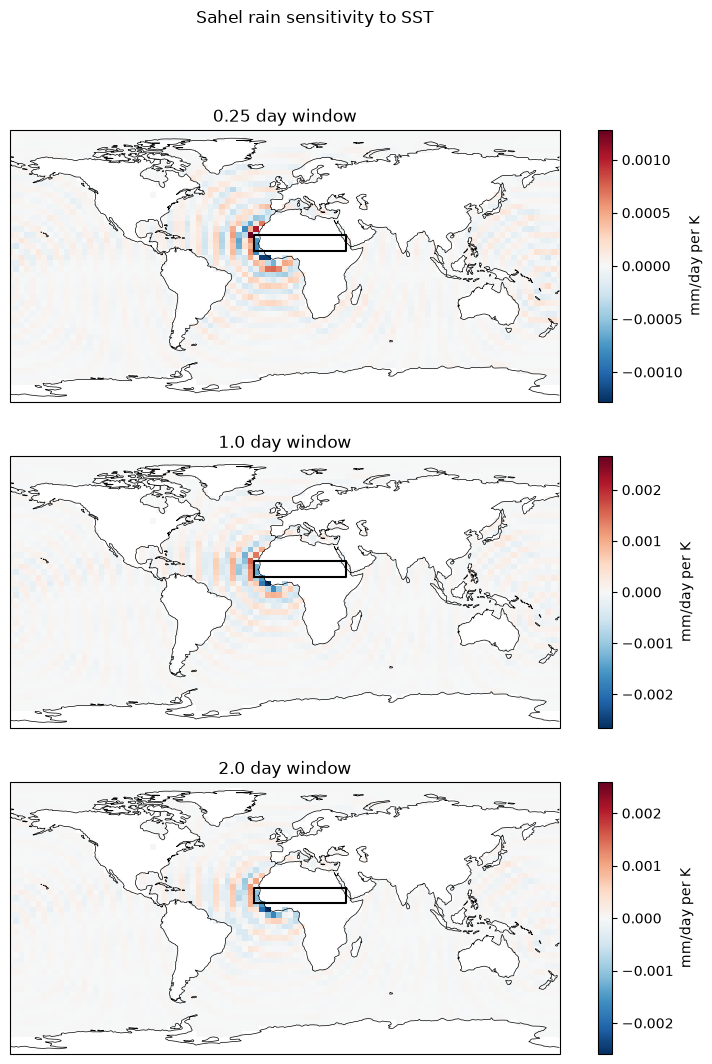

In [6]:
def per_area(m):
    return np.where(np.asarray(ocean), m / np.asarray(weights), np.nan)

def draw(ax, m, title, extent=None):
    v = np.nanmax(np.abs(m))
    pc = ax.pcolormesh(lon, lat, m.T, cmap="RdBu_r", vmin=-v, vmax=v, transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.5)
    ax.plot([-20, 40, 40, -20, -20], [10, 10, 20, 20, 10], "k", transform=ccrs.PlateCarree())
    if extent:
        ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_title(title)
    return pc

fig, axs = plt.subplots(len(WINDOWS), 1, figsize=(10, 4 * len(WINDOWS)),
                        subplot_kw=dict(projection=ccrs.PlateCarree()))
for ax, window in zip(axs, WINDOWS):
    pc = draw(ax, per_area(res[window]["map"]), f"{window} day window")
    plt.colorbar(pc, ax=ax, label="mm/day per K")
fig.suptitle("Sahel rain sensitivity to SST")
plt.savefig("../figures/week6_task5_sahel_maps.png", dpi=110)
plt.show()

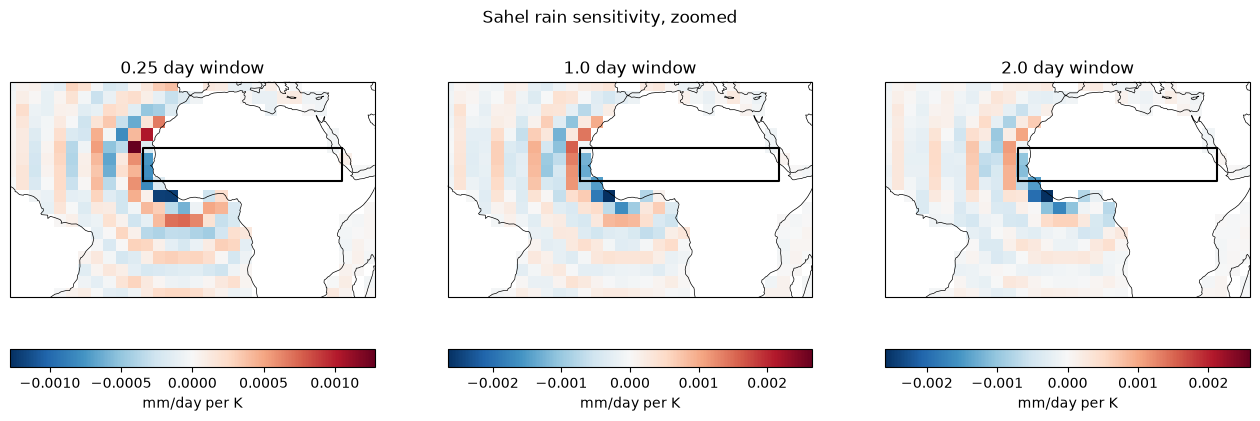

In [7]:
fig, axs = plt.subplots(1, len(WINDOWS), figsize=(16, 4.5), subplot_kw=dict(projection=ccrs.PlateCarree()))
for ax, window in zip(axs, WINDOWS):
    pc = draw(ax, per_area(res[window]["map"]), f"{window} day window", extent=[-60, 50, -25, 40])
    plt.colorbar(pc, ax=ax, orientation="horizontal", label="mm/day per K")
fig.suptitle("Sahel rain sensitivity, zoomed")
plt.savefig("../figures/week6_task5_sahel_zoom.png", dpi=110)
plt.show()

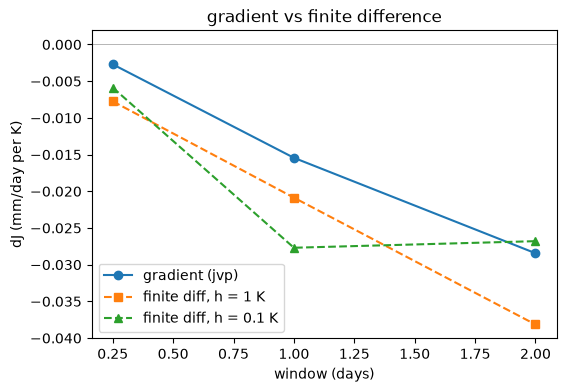

In [8]:
# Gradient vs finite difference against window length
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(WINDOWS, [res[x]["jvp"] for x in WINDOWS], "o-", label="gradient (jvp)")
ax.plot(WINDOWS, [res[x]["fd1"] for x in WINDOWS], "s--", label="finite diff, h = 1 K")
ax.plot(WINDOWS, [res[x]["fd01"] for x in WINDOWS], "^--", label="finite diff, h = 0.1 K")
ax.axhline(0, c="0.6", lw=0.5)
ax.set_xlabel("window (days)")
ax.set_ylabel("dJ (mm/day per K)")
ax.set_title("gradient vs finite difference")
ax.legend()
plt.savefig("../figures/week6_task5_grad_vs_fd.png", dpi=110)
plt.show()

In [9]:
# Save maps (per grid point, not divided by weights) and the scalar results
ds = xr.Dataset(
    {"sensitivity": (("window", "lon", "lat"), np.stack([res[x]["map"] for x in WINDOWS]),
                     {"units": "mm/day per K", "long_name": "dJ/dSST per grid point (Sahel rain, includes area weight)"})},
    coords={"window": ("window", WINDOWS, {"units": "days"}), "lon": lon, "lat": lat},
)
for k in ["J0", "jvp", "fd1", "fd01", "t_fwd", "t_rev"]:
    ds[k] = ("window", [res[x][k] for x in WINDOWS])
ds["ocean_mask"] = (("lon", "lat"), np.asarray(ocean).astype(int))
ds.to_netcdf("../results/w6-task5_sahel.nc")
ds

<xarray.Dataset> Size: 93kB
Dimensions:      (window: 3, lon: 96, lat: 48)
Coordinates:
  * window       (window) float64 24B 0.25 1.0 2.0
  * lon          (lon) float64 768B 0.0 3.75 7.5 11.25 ... 348.8 352.5 356.2
  * lat          (lat) float64 384B -87.16 -83.48 -79.78 ... 79.78 83.48 87.16
Data variables:
    sensitivity  (window, lon, lat) float32 55kB 0.0 0.0 ... 1.971e-06 -1.81e-07
    J0           (window) float64 24B 0.8131 0.49 0.4187
    jvp          (window) float64 24B -0.002702 -0.01544 -0.02844
    fd1          (window) float64 24B -0.007743 -0.02087 -0.03815
    fd01         (window) float64 24B -0.005875 -0.02769 -0.0268
    t_fwd        (window) float64 24B 12.17 13.03 14.97
    t_rev        (window) float64 24B 23.51 23.88 25.01
    ocean_mask   (lon, lat) int64 37kB 0 0 0 0 0 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1

## Interpretation

**Why the gradient and the finite difference differ.** SPEEDY's convection and large-scale condensation switch on
when thresholds are crossed. The gradient only sees the smooth part of the response at the current state. The
finite difference also picks up grid points where convection switches on or off. That is why the finite difference
is larger and depends on h: a bigger h crosses more thresholds. Rainfall is more switch-driven than OLR, so the
gap should be larger than in Task 3.1. The 2-day h = 0.1 K value happens to sit on the gradient, but h = 1 K does
not, so that looks like luck rather than convergence. Chaos adds more spread as the window grows (Task 4).

**What the map shows.** In 1-2 days air only travels a few grid cells, so only nearby ocean can affect the Sahel.
The strongest values are the two ocean points inside the box (the Senegal coast) and the coast just south of it.
Warming them lowers Sahel rain. A possible reason is that warmer coastal water makes convection and rain happen
over the coast and ocean, so less moisture is carried inland. This is a hypothesis; a longer window or a check of
evaporation and low-level winds would be needed to confirm it.

**Spectral ringing.** The alternating red and blue stripes across the Atlantic (and faint rings over the Pacific in
the global map) come from the T31 spectral transform. A change at one grid point spreads as a pattern of waves in
spectral space. They are not physical teleconnections: nothing can reach the Sahel from the Pacific in a day.

**Caveat.** The Sahel box has only 2 ocean points, and J is a short-window average, so this tells us about the fast,
local response, not the seasonal monsoon response to SST (for example to Atlantic or Pacific patterns) that matters
for climate. That would need much longer windows, where single-run gradients stop being reliable (Task 4).